# CPU, cuDF, and Triton TPC-H-derived comparison

This notebook runs and visualizes the repository's PDS-H benchmark suite. PDS-H is derived from TPC-H and is not an official TPC-H publication benchmark. Set `PDSH_SCALE_FACTOR` to choose the generated dataset size (for example, `0.01`, `1`, or `10`). If no dataset is configured, the setup uses the matching legacy polars-benchmark dataset when available, then falls back to a local TPC-H-compatible Parquet dataset.

Set `PDSH_DATASET_PATH` to use an existing dataset. Otherwise, the notebook first checks `../polars-benchmark/data/tables/scale-{PDSH_SCALE_FACTOR}.0`, matching the older benchmark, and then checks the repository dataset locations. The setup discovers the dataset, runs all configured backends with the streaming GPU executor and a warm-up iteration, loads the results, and renders the plots.

In [3]:
from pathlib import Path
import json
import os
import shlex
import subprocess

import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
scale_factor = 9 # float(os.environ.get("PDSH_SCALE_FACTOR", "1"))
scale_label = f"{scale_factor:g}"
triton_executor = "in-memory" if scale_factor <= 5 else "streaming"
results_dir = repo_root / "tpch_backend_results" / f"scale-{scale_label}"
dataset_candidates = [
    Path(os.environ["PDSH_DATASET_PATH"])
    if os.environ.get("PDSH_DATASET_PATH")
    else None,
    repo_root.parent / "polars-benchmark" / "data" / "tables" / f"scale-{scale_label}.0",
    repo_root / "datasets" / "tables" / f"scale-{scale_label}.0",
]
dataset_candidates = [path for path in dataset_candidates if path is not None]
dataset_path = next(
    (path for path in dataset_candidates if (path / "lineitem.parquet").exists()),
    dataset_candidates[0]
    if dataset_candidates
    else repo_root / "datasets" / "tables" / f"scale-{scale_label}",
)

PARAMETERS = {
    "dataset_path": str(dataset_path),
    "queries": "1",
    "iterations": 1,
    "backends": ["triton", "cudf"],
    "results_dir": str(results_dir),
    "suffix": ".parquet",
    "scale_factor": scale_factor,
    "triton_executor": triton_executor,
}


Running: PYTHONPATH=python/cudf_polars python -m cudf_polars.streaming.benchmarks.compare_backends 1 --path /home/andri/polars-benchmark/data/tables/scale-9.0 --iterations 1 --suffix .parquet --backends triton,cudf --executor streaming --triton-executor streaming --warmup --output-dir /home/andri/cudf/tpch_backend_results/scale-9
Query 1 - Iteration 0 finished in 1.5307s
Query 1 - Iteration 1 finished in 0.8864s
✅ Query 1 - Iteration 0 finished in 2.3862s
✅ Query 1 - Iteration 1 finished in 75.0740s

Validation Summary
✅ All validated queries passed.
✅ Query 1 - Iteration 0 finished in 1.5696s
✅ Query 1 - Iteration 1 finished in 0.8494s

Validation Summary
✅ All validated queries passed.
cpu q1: 0.886386s
triton q1: 75.074033s, speedup_vs_cpu=0.012x
cudf q1: 0.849385s, speedup_vs_cpu=1.044x
Wrote comparison to /home/andri/cudf/tpch_backend_results/scale-9/summary.json



,backend,query,mean_seconds,speedup_vs_cpu
0,cpu,1,0.886386,NaN
1,cudf,1,0.849385,1.043562
2,triton,1,75.074033,0.011807


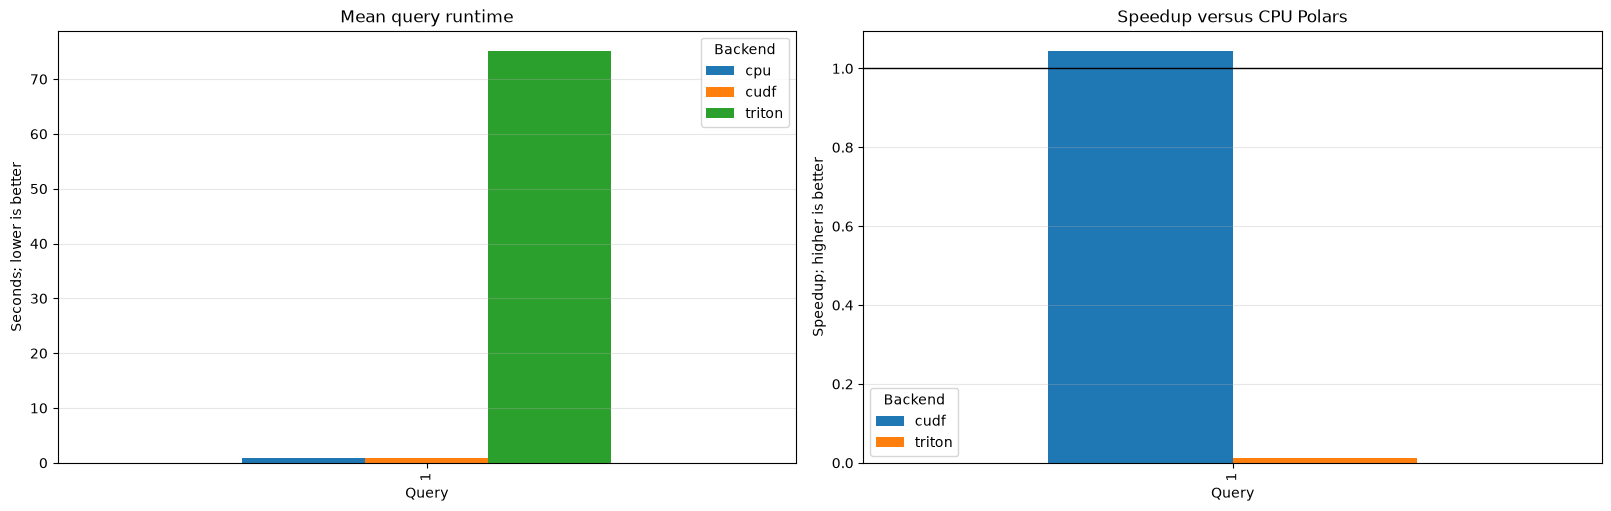

In [4]:
def display_parameters(parameters=PARAMETERS):
    """Display the active benchmark configuration."""
    return pd.Series(parameters, name="value").rename_axis("parameter").reset_index()


def benchmark_command(parameters=PARAMETERS):
    """Build the benchmark command."""
    return [
        "python", "-m",
        "cudf_polars.streaming.benchmarks.compare_backends",
        parameters.get("queries") or "all",
        "--path", parameters["dataset_path"],
        "--iterations", str(parameters["iterations"]),
        "--suffix", parameters["suffix"],
        "--backends", ",".join(parameters["backends"]),
        "--executor", "streaming",
        "--triton-executor", parameters["triton_executor"],
        "--warmup",
        "--output-dir", parameters["results_dir"],
    ]


def run_benchmark(parameters=PARAMETERS):
    """Run every configured backend and return the generated summary path."""
    dataset = Path(parameters["dataset_path"])
    if not ((dataset / "lineitem.parquet").exists() or (dataset / "lineitem").is_dir()):
        raise NotImplementedError("Does not have a dataset!")
        # try:
        #     import duckdb
        # except ImportError as error:
        #     raise RuntimeError(
        #         "No PDS-H dataset was found and DuckDB is not installed. "
        #         "Install duckdb or set PDSH_DATASET_PATH to a directory "
        #         "containing the PDS-H parquet tables."
        #     ) from error
        # dataset.mkdir(parents=True, exist_ok=True)
        # connection = duckdb.connect()
        # try:
        #     connection.execute("INSTALL tpch")
        #     connection.execute("LOAD tpch")
        #     connection.execute(f"CALL dbgen(sf={parameters['scale_factor']})")
        #     tables = ("customer", "lineitem", "nation", "orders", "part", "partsupp", "region", "supplier")
        #     for table in tables:
        #         output = (dataset / f"{table}.parquet").as_posix()
        #         connection.execute(f"COPY {table} TO '{output}' (FORMAT PARQUET)")
        # finally:
        #     connection.close()
    completed = subprocess.run(
        benchmark_command(parameters),
        cwd=repo_root,
        env={**os.environ, "PYTHONPATH": str(repo_root / "python" / "cudf_polars")},
        check=False,
        text=True,
        capture_output=True,
    )
    if completed.stdout:
        print(completed.stdout)
    if completed.returncode != 0:
        raise RuntimeError(
            "The benchmark failed.\n"
            f"stdout:\n{completed.stdout}\n"
            f"stderr:\n{completed.stderr}"
        )
    return Path(parameters["results_dir"]) / "summary.json"


def load_summary(path):
    """Load summary.json into a long-form DataFrame."""
    summary_path = Path(path) / "summary.json"
    summary = json.loads(summary_path.read_text())
    rows = []
    for backend, queries in summary["timings_seconds"].items():
        for query, timing in queries.items():
            rows.append({
                "backend": backend,
                "query": int(query),
                "mean_seconds": timing["mean"],
                "samples": timing["samples"],
                "speedup_vs_cpu": summary.get("speedup_vs_cpu", {}).get(backend, {}).get(query),
            })
    return pd.DataFrame(rows).sort_values(["query", "backend"]).reset_index(drop=True)


def plot_mean_runtime(data, ax=None):
    """Plot mean runtime in seconds for each query and backend."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    data.pivot(index="query", columns="backend", values="mean_seconds").plot.bar(ax=ax)
    ax.set(title="Mean query runtime", xlabel="Query", ylabel="Seconds; lower is better")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Backend")
    return ax


def plot_speedup_vs_cpu(data, ax=None):
    """Plot speedup relative to CPU Polars; values above one are faster."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    data.dropna(subset=["speedup_vs_cpu"]).pivot(
        index="query", columns="backend", values="speedup_vs_cpu"
    ).plot.bar(ax=ax)
    ax.axhline(1.0, color="black", linewidth=1)
    ax.set(title="Speedup versus CPU Polars", xlabel="Query", ylabel="Speedup; higher is better")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Backend")
    return ax


display_parameters()
print("Running:", "PYTHONPATH=python/cudf_polars " + " ".join(shlex.quote(part) for part in benchmark_command()))
summary_path = run_benchmark()
results = load_summary(summary_path.parent)
display(results.drop(columns="samples"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
plot_mean_runtime(results, axes[0])
plot_speedup_vs_cpu(results, axes[1])
plt.show()
